# Experiment 6: Customer Segmentation using K-Means Clustering
**Aim:** To perform customer segmentation using K-Means clustering, determine the optimal number of clusters using the Elbow Method, and interpret the customer groups.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

### A) Dataset Loading and Feature Selection

In [3]:
df = pd.read_csv("../Datasets/Mall_Customers.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

# Select Annual Income and Spending Score
data = df.iloc[:, [3, 4]].values

Dataset Shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicate Rows: 0


### B) Elbow Method to Find Optimal Clusters

WCSS (K=1-5): [269981.28, 181363.6, 106348.37, 73679.79, 44448.46]
WCSS (K=6-10): [37233.81, 30241.34, 25036.42, 21916.79, 20072.07]


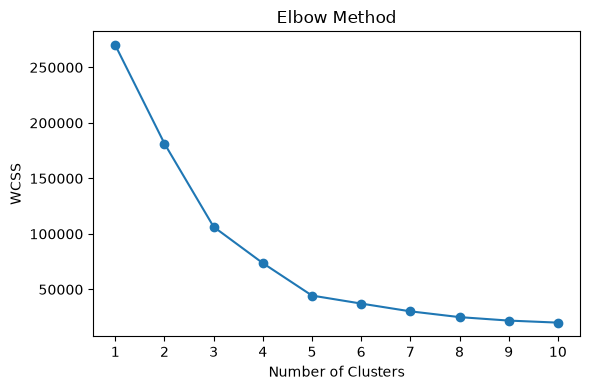

In [4]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42, n_init=10)
    kmeans.fit(data)
    wcss.append(kmeans.inertia_)

print("WCSS (K=1-5):", [round(v, 2) for v in wcss[:5]])
print("WCSS (K=6-10):", [round(v, 2) for v in wcss[5:]])

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

### C) K-Means Clustering (K = 5) and Cluster Interpretation

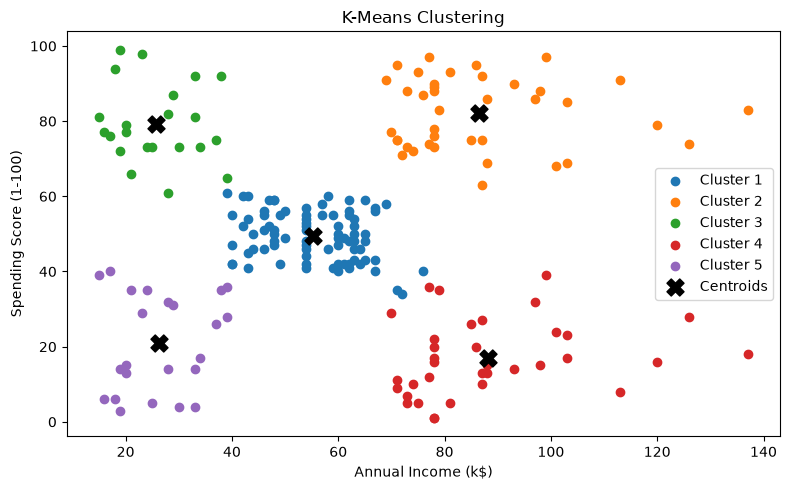

Average Income and Spending Score per Cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91

First 5 Records with Cluster Labels:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  


In [5]:
kmeans = KMeans(n_clusters=5, init="k-means++", random_state=42, n_init=10)
y_pred = kmeans.fit_predict(data)

plt.figure(figsize=(8, 5))
for i in range(5):
    plt.scatter(
        data[y_pred == i, 0],
        data[y_pred == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=150, c="black", marker="X", label="Centroids"
)
plt.title("K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()

df["Cluster"] = y_pred
print("Average Income and Spending Score per Cluster:")
print(df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean().round(2))

print("\nFirst 5 Records with Cluster Labels:")
print(df.head())